# 3.1 · A multi-factor long-only strategy

> **Needs:** the research cache (notebook 1.1) and the database, where every run is registered. The run registry, the deflated Sharpe ratio and the hold-out it relies on are explained in notebook 3.4.
>
> **Produces:** five registered runs of the family `multi_factor_lo`; notebooks 3.2, 3.3 and 4.3 build on its second version.

Most investors cannot, or may not, sell short. A **long-only** strategy holds only the best-scoring stocks. It has a
market beta near 1, so its return is dominated by the market's; the question becomes whether it **outperforms a
passive investment in the same universe**, net of costs.

| Factor | Economic intuition | Measurement |
|---|---|---|
| **Value** | cheap stocks earn a premium (risk compensation or investor over-extrapolation) | earnings, sales, book value and operating profit relative to market capitalisation |
| **Quality** | profitable, conservatively financed firms are under-priced | return on equity and on invested capital, gross profit to assets, low leverage |
| **Momentum** | past 12-month winners keep outperforming for some months (under-reaction) | the return over the past 12 months excluding the most recent month |
| **Low volatility** | low-risk stocks earn more risk-adjusted return than the CAPM predicts | low standard deviation of daily returns over the past year |

Each factor is standardised cross-sectionally into a **z-score** per stock and month, and the four z-scores are
averaged into one **composite score** (a weighted mean: the weights are parameters in the first code cell,
`FACTOR_WEIGHTS` and `SECOND_WEIGHTS` for the second version, equal by default).

**Portfolio rules:**

* **Universe:** the S&P 1500 constituents as of each date - 500 large, 400 mid and 600 small caps - never today's list
  applied to the past.
* **Monthly rebalance:** buy the top decile by composite score (about 150 stocks; with the buffer below, about 200 are
  held), equally weighted. A holding is kept until it leaves the top quintile (the buffer reduces turnover).
* **Transaction costs:** 0.10 % per trade for large caps, 0.25 % for mid caps and 0.50 % for small caps. Results are
  net of costs.

**Benchmarks.** Choosing the right benchmark matters, because a portfolio can beat the wrong one simply through its
construction:

| Benchmark | Description | What beating it shows |
|---|---|---|
| **SPTM** | an ETF tracking the S&P Composite 1500, cap-weighted | the strategy beats a passive investment in the same universe |
| **Equal-weight S&P 1500** | the same constituents, equally weighted and rebalanced quarterly, built from our data | equal weighting alone is a tilt towards smaller stocks; beating this benchmark isolates what the *factor selection* added |
| **SPY** | the S&P 500 ETF | the familiar market benchmark |

In [2]:
from dataclasses import replace

import pandas as pd
from IPython.display import display

from equity_research.analytics.indices import equal_weighted, vendor_returns
from equity_research.data.cache import ResearchCache
from equity_research.data.sectors import listing_sectors
from equity_research.data.universe import load_universe_data
from equity_research.strategies.factor_strategy import StrategyConfig, run_strategy
from research_core import charts
from research_core.analytics.performance.metrics import active_performance, performance
from research_core.analytics.performance.tracking import calendar_years
from research_core.data.db.engine import get_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
TODAY = pd.Timestamp.today().strftime("%Y-%m-%d")

engine = get_engine()
# The composite score is the weighted mean of these factors' z-scores. Only the ratios matter, and any factor
# run_strategy knows can be added (its error lists them). Equal weights are the notebook's registered trials; any
# change is a new trial, so choose the weights before seeing the results.
FACTOR_WEIGHTS = {"value": 1.0, "quality": 1.0, "momentum": 1.0, "low_vol": 1.0}
SECOND_WEIGHTS = {"value": 1.0, "quality": 1.0, "momentum": 1.0, "low_vol": 1.0, "issuance": 1.0}  # the second version
config = StrategyConfig(
    family="multi_factor_lo",
    universe="SP1500",
    start="2000-01-01",
    end="2024-12-31",
    factors=tuple(FACTOR_WEIGHTS.items()),
    enter=0.10,
    exit_=0.20,
    long_only=True,
    beta_neutral=False,
)
result = run_strategy(cache, config, engine=engine)
net = result.backtest.net[result.backtest.net.index >= pd.Timestamp(config.start)]

pool = load_universe_data(cache, config.universe, config.start, config.end)
equal_1500 = equal_weighted(pool.returns, pool.members)["return"]
sptm = vendor_returns(cache, "SPTM", total=True)
spy = vendor_returns(cache, "SPY", total=True)
print("Registered as research run", result.run_id)

left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']


Registered as research run 169


## Strategy against the benchmarks

The same statistics for all four series over the same dates.

In [3]:
days = net.index
table = pd.DataFrame(
    {
        "Strategy (after costs)": performance(net),
        "SPTM (S&P 1500 by size)": performance(sptm.reindex(days)),
        "Equal-weight S&P 1500": performance(equal_1500.reindex(days)),
        "SPY (S&P 500)": performance(spy.reindex(days)),
    }
).T
display(table.style.format({"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}))
m = result.metrics
print(
    f"Turnover: {m['turnover']:.1f} times a year | after {m['trials']} version(s) of this idea, deflated Sharpe"
    f" {m['deflated_sharpe']:.1%} - but of the active return against SPTM only {m['deflated_active_sharpe']:.1%}"
)

,cagr,vol,sharpe,max_drawdown
Strategy (after costs),10.8%,17.1%,0.69,-47%
SPTM (S&P 1500 by size),8.3%,19.6%,0.50,-55%
Equal-weight S&P 1500,10.5%,22.3%,0.56,-60%
SPY (S&P 500),7.9%,19.3%,0.49,-55%


Turnover: 3.0 times a year | after 12 version(s) of this idea, deflated Sharpe 95.8% - but of the active return against SPTM only 25.7%


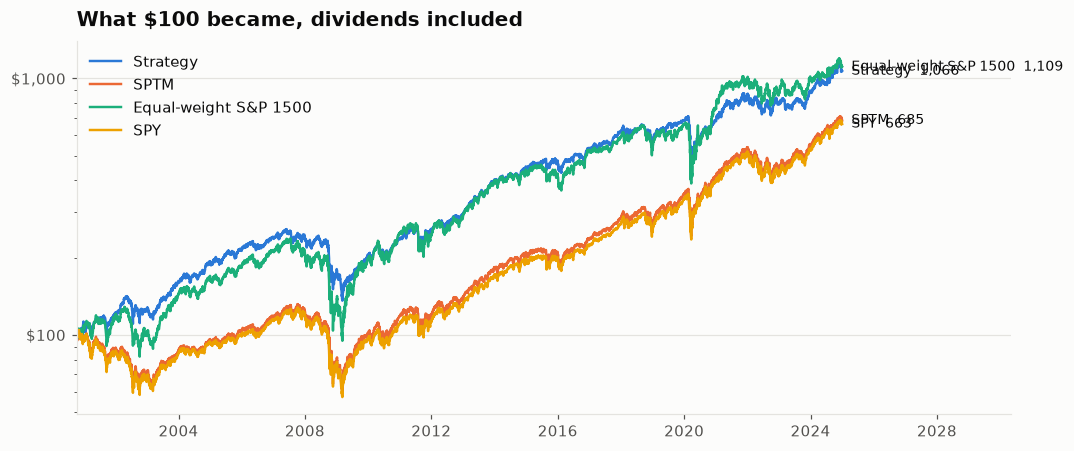

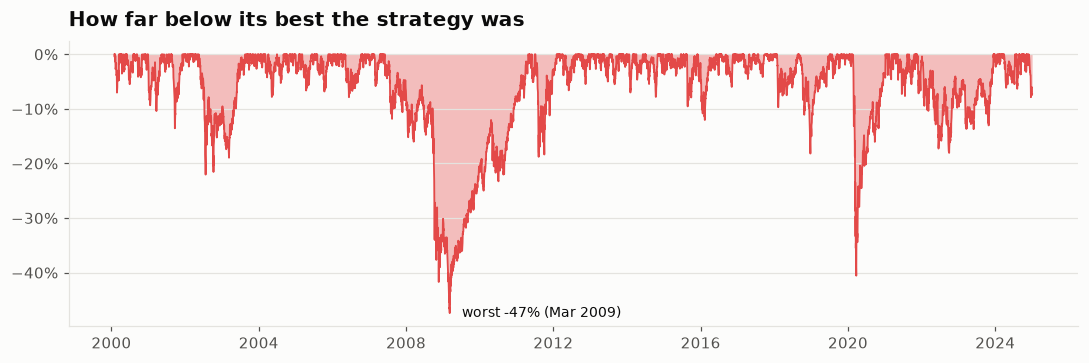

In [4]:
fig = charts.growth(
    {"Strategy": net, "SPTM": sptm, "Equal-weight S&P 1500": equal_1500, "SPY": spy},
    "What $100 became, dividends included",
)
fig = charts.drawdown(net, "How far below its best the strategy was")

## Relative performance

The line is the strategy's cumulative value divided by the equal-weight S&P 1500's (a *relative wealth* curve): rising
means factor selection is adding value over holding every constituent equally, falling means it is detracting.
Factor premia are noisy and arrive in long regimes - value, for example, underperformed for most of 2010-2020 - so a
few bad years do not by themselves refute a factor, and a few good years do not confirm it. With annual volatility of
active returns around 5 %, it takes decades to estimate a 2 % premium with statistical confidence.

,Strategy,SPTM,Equal-weight S&P 1500,SPY
trade_date,,,,
2000,12.2%,-2.7%,7.6%,-4.4%
2001,8.2%,-10.1%,9.3%,-11.8%
2002,2.2%,-21.6%,-15.4%,-21.6%
2003,29.8%,27.0%,44.2%,28.2%
2004,20.0%,10.6%,18.2%,10.7%
2005,9.8%,6.7%,7.7%,4.8%
2006,12.5%,14.8%,16.0%,15.8%
2007,0.8%,5.2%,-1.2%,5.1%
2008,-25.9%,-36.7%,-36.1%,-36.8%


Beta to SPTM: 0.77 (1.0 = moves exactly with the market)


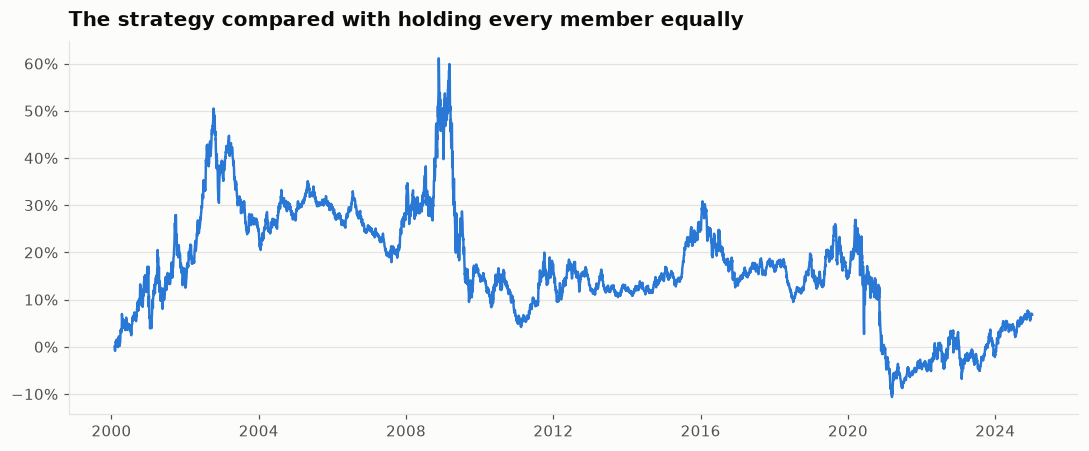

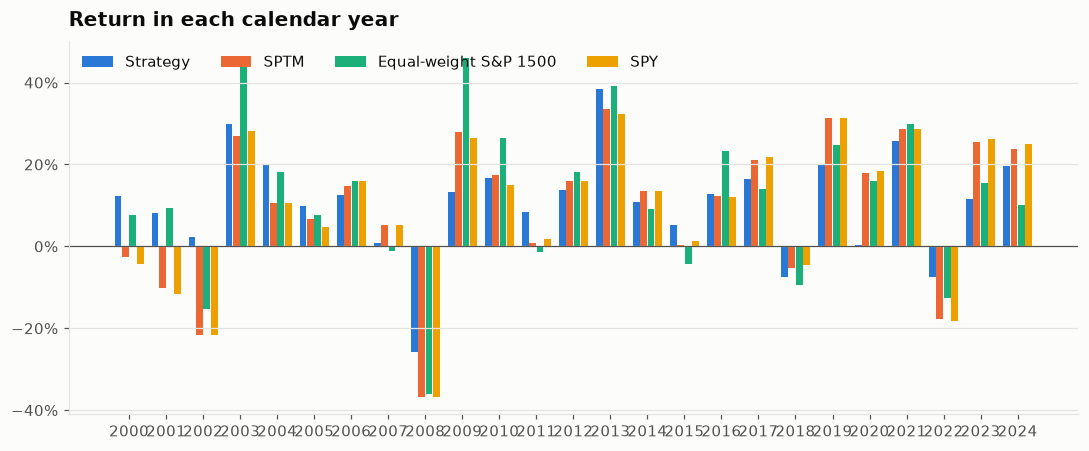

In [5]:
both = pd.concat({"strategy": net, "equal": equal_1500}, axis=1, sort=True).dropna()
relative = (1 + both["strategy"]).cumprod() / (1 + both["equal"]).cumprod() - 1
fig = charts.lines(
    {"strategy ahead of the equal-weight S&P 1500 by": relative},
    "The strategy compared with holding every member equally",
    percent=True,
)
years = calendar_years({"Strategy": net, "SPTM": sptm, "Equal-weight S&P 1500": equal_1500, "SPY": spy})
fig = charts.yearly_bars(years, "Return in each calendar year")
display(years.style.format("{:.1%}"))
print(f"Beta to SPTM: {active_performance(net, sptm)['beta']:.2f} (1.0 = moves exactly with the market)")

## Portfolio composition

The portfolio at its last rebalance inside the test period: the number of holdings, the split between large, mid and
small caps, and the sector allocation. (Sectors are point-in-time; our sector history starts on the day it was first
recorded, so for earlier dates the earliest recorded classification is used.)

206 companies on 31 December 2024


,companies
2024-12-31 00:00:00,
large,100
mid,58
small,48


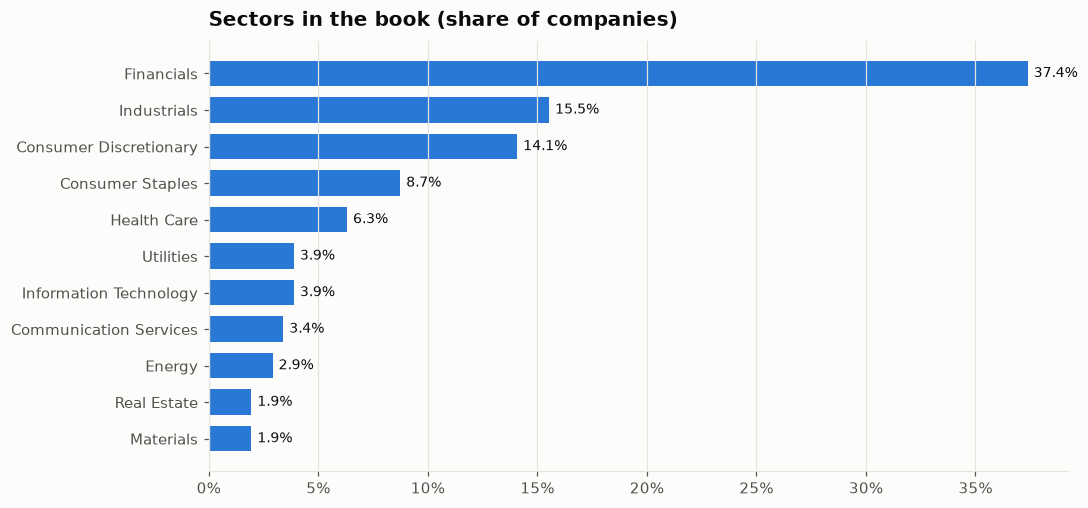

In [6]:
last = result.book.iloc[-1]
held = last[last > 0]
day = result.book.index[-1]
print(f"{len(held)} companies on {day:%d %B %Y}")
display(pool.segment.loc[day, held.index].value_counts().rename("companies").to_frame())
sectors = listing_sectors(cache, held.index, day).value_counts(normalize=True)
fig = charts.ranked_bars(sectors, "Sectors in the book (share of companies)", percent=True)

## A second version: broader holdings, cap-weighted

Analysis of the first version found three things:

* **The composite works mainly on the short side.** The bottom decile underperformed the universe by about 2 % a
  year, while the top decile did no better than the average constituent. A long-only portfolio cannot short the
  losers, but it can avoid them and hold most of the rest.
* **Equal weighting is a bet in itself.** It puts about a quarter of the portfolio in small caps and little in the
  largest companies, and gives a beta below 1. In years led by mega-caps (2019, 2020, 2023) this size tilt cost more
  than the factors added.
* **Net share issuance predicts returns.** Firms issuing shares have underperformed firms buying theirs back (Pontiff
  and Woodgate, 2008) - a fifth factor with low correlation to the other four.

The second version therefore keeps the scores, adds the fifth factor, and changes the portfolio construction:

| Setting | First version | Second version |
|---|---|---|
| Factors | value, quality, momentum, low volatility | the same four plus **net issuance**: the change in shares outstanding over the past year (buybacks score well) |
| Selection | top decile (held until it leaves the top quintile) | top 30 % (held until it leaves the top 40 %) |
| Weighting | equal | **market capitalisation**, as in SPTM |

**Caveat - this is not an out-of-sample result.** The second version was designed *after* studying these same years,
and about seven variants were tried along the way without being registered. Its deflated Sharpe counts only the
registered runs, so it overstates the evidence; only the hold-out period (2025 on) can show whether the improvement
is real.

In [7]:
second = replace(
    config,
    factors=tuple(SECOND_WEIGHTS.items()),
    enter=0.30,
    exit_=0.40,
    weighting="market_cap",
)
result2 = run_strategy(cache, second, engine=engine)
net2 = result2.backtest.net[result2.backtest.net.index >= pd.Timestamp(second.start)]
print("Registered as research run", result2.run_id)

lines = {
    "First version": net,
    "Second version": net2,
    "SPTM (S&P 1500 by size)": sptm.reindex(net2.index),
    "Equal-weight S&P 1500": equal_1500.reindex(net2.index),
}
both_versions = pd.DataFrame({name: performance(r) for name, r in lines.items()}).T
both_versions["beta to SPTM"] = [active_performance(r, sptm)["beta"] for r in lines.values()]
both_versions["behind (-) or ahead of SPTM a year"] = [
    active_performance(r, sptm)["active_return"] for r in lines.values()
]
display(
    both_versions.style.format(
        {
            "cagr": "{:.1%}",
            "vol": "{:.1%}",
            "sharpe": "{:.2f}",
            "max_drawdown": "{:.0%}",
            "beta to SPTM": "{:.2f}",
            "behind (-) or ahead of SPTM a year": "{:+.1%}",
        }
    )
)
m2 = result2.metrics
print(
    f"Second version: {(result2.book.iloc[-1] > 0).sum()} companies, turnover {m2['turnover']:.1f} times a year"
    f" (first: {m['turnover']:.1f}) | deflated Sharpe {m2['deflated_sharpe']:.1%} after {m2['trials']} registered"
    " version(s)"
)

left out 1078 facts of 2 companies in ['GBP']


Registered as research run 170


,cagr,vol,sharpe,max_drawdown,beta to SPTM,behind (-) or ahead of SPTM a year
First version,10.8%,17.1%,0.69,-47%,0.77,+1.8%
Second version,8.9%,17.3%,0.58,-45%,0.80,+1.1%
SPTM (S&P 1500 by size),8.3%,19.6%,0.50,-55%,1.00,+0.0%
Equal-weight S&P 1500,10.5%,22.3%,0.56,-60%,1.17,+2.0%


Second version: 522 companies, turnover 1.5 times a year (first: 3.0) | deflated Sharpe 88.0% after 13 registered version(s)


,First version,Second version,SPTM
trade_date,,,
2000,12.2%,4.1%,-2.7%
2001,8.2%,-3.9%,-10.1%
2002,2.2%,-9.8%,-21.6%
2003,29.8%,20.1%,27.0%
2004,20.0%,10.9%,10.6%
2005,9.8%,7.1%,6.7%
2006,12.5%,15.9%,14.8%
2007,0.8%,4.4%,5.2%
2008,-25.9%,-27.6%,-36.7%


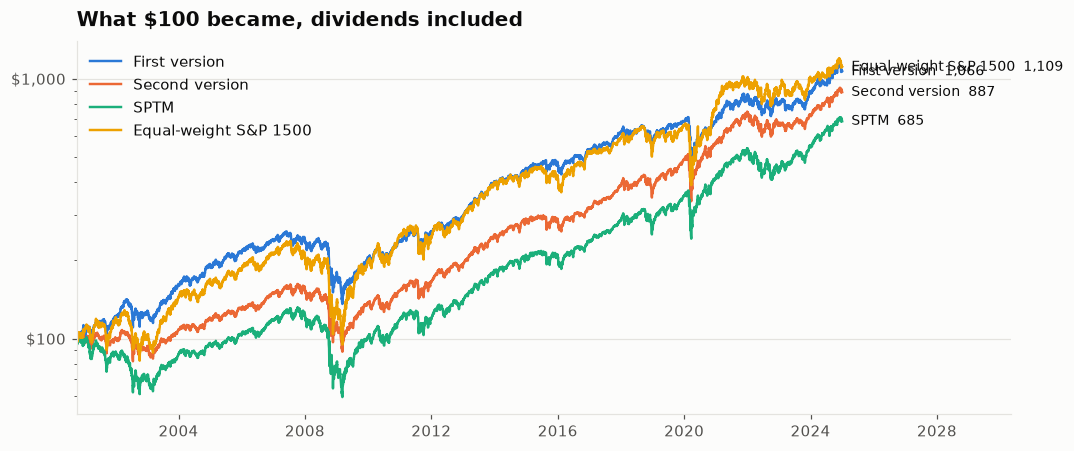

In [8]:
fig = charts.growth(
    {"First version": net, "Second version": net2, "SPTM": sptm, "Equal-weight S&P 1500": equal_1500},
    "What $100 became, dividends included",
)
years2 = calendar_years({"First version": net, "Second version": net2, "SPTM": sptm})
display(years2.style.format("{:.1%}"))

## Active performance and robustness

A long-only portfolio's own Sharpe ratio mostly measures the market it holds: both versions' deflated Sharpe is near
100 % because equities rose from 2010 to 2024, not because the factors worked. The relevant test is on the **active
return** - the strategy's return minus SPTM's:

| Measure | Definition |
|---|---|
| **Active return** | annualised return of the strategy minus that of SPTM |
| **Tracking error** | annualised standard deviation of the active return |
| **Information ratio** | active return divided by tracking error: the Sharpe ratio of the active bet (0.5 is good) |
| **Deflated active Sharpe** | the probability that the active bet reflects skill rather than luck, given every trial of the hypothesis |

Two robustness checks that introduce no new design choices, only more history and another vendor's data:

* **From 2006:** LSEG's statements extend before the SEC's XBRL filings (2009-2011), so the same rules can be tested
  through the 2008 financial crisis - years that played no part in designing the second version, which makes this
  closer to an out-of-sample test.
* **LSEG statements instead of the SEC's:** a result that holds with only one vendor's figures is fragile. (LSEG keeps
  restated figures dated by their first announcement, so a later restatement can appear early - a small look-ahead.)

In [9]:
runs = {
    "First version, 2010-2024": result,
    "Second version, 2010-2024": result2,
    "First version, 2006-2024": run_strategy(cache, replace(config, start="2006-01-01"), engine=engine),
    "Second version, 2006-2024": run_strategy(cache, replace(second, start="2006-01-01"), engine=engine),
    "Second version, LSEG accounts": run_strategy(
        cache, replace(second, fundamentals_vendor="refinitiv"), engine=engine
    ),
}
ACTIVE = {
    "cagr": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.0%}",
    "beta": "{:.2f}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
}
display(pd.DataFrame({name: r.metrics for name, r in runs.items()}).T[list(ACTIVE)].style.format(ACTIVE))
print("Registered as research runs", [r.run_id for r in runs.values()])

early = {name: r.backtest.net for name, r in runs.items() if "2006" in name} | {"SPTM": sptm}
early_years = calendar_years(early)
display(early_years.loc[early_years.index <= 2009].style.format("{:.1%}"))

left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']
left out 1078 facts of 2 companies in ['GBP']


,cagr,sharpe,max_drawdown,beta,active_return,tracking_error,information_ratio,deflated_active_sharpe
"First version, 2010-2024",10.8%,0.69,-47%,0.77,+1.8%,7.7%,+0.21,26%
"Second version, 2010-2024",8.9%,0.58,-45%,0.80,+1.1%,5.3%,+0.14,15%
"First version, 2006-2024",8.7%,0.56,-47%,0.84,-1.6%,6.4%,-0.28,0%
"Second version, 2006-2024",10.6%,0.66,-45%,0.85,+0.2%,4.2%,-0.01,4%
"Second version, LSEG accounts",8.8%,0.57,-45%,0.80,+1.0%,5.3%,+0.12,12%


Registered as research runs [169, 170, 171, 172, 173]


,"First version, 2006-2024","Second version, 2006-2024",SPTM
trade_date,,,
2006,7.7%,13.5%,11.2%
2007,0.8%,4.4%,5.2%
2008,-25.9%,-27.6%,-36.7%
2009,13.4%,20.6%,28.0%


## Glossary

* **Factor** - a measurable stock characteristic associated with differences in expected returns.
* **z-score** - a value's distance from the cross-sectional mean in standard deviations; 0 is average.
* **Rebalance** - the date the portfolio is traded back to its target holdings (here: every month end).
* **Turnover** - the fraction of the portfolio traded per year; 3.0 means the whole book is replaced three times.
* **Sharpe ratio** - annualised excess return divided by annualised volatility: return per unit of total risk. For an
  equity strategy, above 0.5 is respectable and above 1 is strong.
* **Maximum drawdown** - the largest peak-to-trough decline (the deepest point of the drawdown chart).
* **Hold-out** - the most recent years, reserved for a single out-of-sample test.
* **Active return** - the strategy's return minus its benchmark's (here SPTM): the value added or lost by stock
  selection and weighting.
* **Capitalisation weights** - weights proportional to each company's total market capitalisation, as in SPTM (a
  company with two share classes, like Alphabet, has its capitalisation split between them).
* **Net issuance** - the growth in a company's shares outstanding over the past year: new shares (sold, or issued as
  employee compensation) dilute existing holders; buybacks do the opposite.

**See also:** notebook 4.3 applies the same scores to rank today's constituents.